# 03 · Handle missing data — EDA Step 3

**Goal:** on the trust-only canonical table, separate three different kinds of "absence" so
later steps don't confuse them:

1. **Short-history / partial trusts** — a trust that isn't present in all 61 months.
2. **True gaps** — a `(trust, dept)` series that starts, stops, then resumes (an internal hole).
3. **Structural zeros** — a `(trust, dept)` that never appears because the trust simply doesn't
   offer that specialty (not missing — legitimately absent).

**Outputs:** `results/balanced_panel_trusts.csv`, `results/series_coverage.csv`,
`results/dept_ubiquity.csv`, and a coverage figure. These feed **Step 4 (selection)**.

Kernel: **FedOPD (.venv)**.

## Cell 1 — setup: load the trust-only canonical table

- We find the repo root by walking up until we see `src/rtt.py`, so the notebook runs from any
  folder / any machine (no hard-coded path).
- `pd.read_parquet(...)` loads the table built in Step 2 (`data/processed/`).
- `months` = the sorted list of distinct month-starts; `N` = how many there are (**61**);
  `midx` maps each month to an integer 0…60 so we can measure spans and gaps.

In [1]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'src' / 'rtt.py').exists():
            return p
    raise FileNotFoundError('repo root not found')

REPO = find_repo()
RESULTS = Path.cwd() / 'results'; RESULTS.mkdir(exist_ok=True)
FIGS = REPO / 'reports' / 'figures'; FIGS.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(REPO / 'data' / 'processed' / 'rtt_trusts_canonical.parquet')
months = np.sort(df['date'].unique())
N = len(months)
midx = {d: i for i, d in enumerate(months)}

print(f'rows {len(df):,} | months {N} | trusts {df.branch.nunique()} | depts {df.dept.nunique()}')
print('range:', pd.Timestamp(months[0]).date(), '->', pd.Timestamp(months[-1]).date())

rows 150,350 | months 61 | trusts 172 | depts 23
range: 2021-04-01 -> 2026-04-01


## Cell 2 — trust-level coverage → the balanced panel

A trust is **balanced** if it reports in *all* 61 months. Forecasting hates gaps, so the balanced
trusts are our day-1 client pool.

- We aggregate to **one row per trust** with `groupby('branch').agg(...)`.
- `months_present` = distinct months the trust appears in; `== N` flags the fully-present ones.
- **Note:** we take the trust's *most recent* `icb` with `'last'` — ICB codes change over time
  (the July-2022 CCG→ICB switch), so a trust has several ICB labels across the 61 months; keeping
  every combination would double-count trusts. `'last'` = its current ICB.

In [2]:
tc = df.groupby('branch').agg(
    months_present=('date', 'nunique'),
    branch_name=('branch_name', 'last'),
    icb=('icb', 'last'),
    icb_name=('icb_name', 'last'),
).reset_index()
tc['balanced'] = tc['months_present'] == N
bal = tc.loc[tc['balanced'], 'branch']

print(f'balanced trusts (all {N} months): {len(bal)} of {len(tc)}')
print('\nmonths-present -> #trusts:')
print(tc['months_present'].value_counts().sort_index(ascending=False).to_string())

balanced trusts (all 61 months): 138 of 172

months-present -> #trusts:
months_present
61    138
60      5
59      1
58      3
56      1
53      1
51      1
47      1
45      1
42      1
41      1
38      1
36      2
35      3
34      6
27      1
26      1
24      1
23      1
12      1
6       1


## Cell 3 — series completeness: full vs true-gap vs short-history

Now at the `(trust, dept)` **series** grain. For each series we compute:
- `mp` = months present; `fi`/`li` = first/last month index; `span` = `li - fi + 1`.
- `gaps` = `span - mp` → **internal holes** (a true-missing month inside the active window).

Classification:
- **full** — present in all 61 months.
- **true-gap** — has internal holes (report, then stop, then resume).
- **short-history** — contiguous but started late / ended early (e.g. a new service line).

In [3]:
g = df.groupby(['branch', 'dept'])
s = pd.DataFrame({'mp': g['date'].nunique(),
                  'fi': g['date'].min().map(midx),
                  'li': g['date'].max().map(midx)}).reset_index()
s['span'] = s['li'] - s['fi'] + 1
s['gaps'] = s['span'] - s['mp']
s['kind'] = np.where(s['mp'] == N, 'full',
             np.where(s['gaps'] > 0, 'true-gap', 'short-history'))

print(f'series (trust x dept): {len(s):,}')
print(s['kind'].value_counts().to_string())
print(f"\ntrue-missing months to handle (sum of internal gaps): {int(s['gaps'].sum()):,}")

series (trust x dept): 2,739
kind
full             2056
true-gap          416
short-history     267

true-missing months to handle (sum of internal gaps): 4,267


## Cell 4 — structural zeros (a trust simply doesn't offer a dept)

Across the **balanced** trusts, how many `trust × dept` combinations *never* appear? Those are
**structural** — the trust doesn't run that specialty — not data we should impute. Knowing this
share tells us the panel will be sparse if we demand every dept from every trust, which is exactly
why Step 4 selects a *shared* set of departments.

In [4]:
depts = sorted(df['dept'].unique())
present = set(map(tuple, s.loc[s['branch'].isin(bal), ['branch', 'dept']].values))
all_cells = list(itertools.product(bal, depts))
structural = len(all_cells) - len(present)

print(f'balanced {len(bal)} trusts x {len(depts)} depts = {len(all_cells):,} cells')
print(f'present: {len(present):,} | structural-absent: {structural:,} ({structural/len(all_cells):.1%})')

balanced 138 trusts x 23 depts = 3,174 cells
present: 2,409 | structural-absent: 765 (24.1%)


## Cell 5 — department ubiquity (preview of Step 4's first gate)

For each department, among the balanced trusts: how many *offer* it at all, and how many offer it
with a **full** 61-month history (`pct_full`). High `pct_full` = the dept can form a balanced panel
across clients — this is the **ubiquity gate** we'll apply when we pick the final 10 departments.

In [5]:
sb = s[s['branch'].isin(bal)].copy()
sb['full'] = sb['mp'] == N
du = (sb.groupby('dept')
        .agg(offering=('branch', 'nunique'), full=('full', 'sum'))
        .reset_index())
du['pct_full'] = du['full'] / len(bal)
du = du.merge(df[['dept', 'dept_name']].drop_duplicates(), on='dept').sort_values('pct_full', ascending=False)
du[['dept', 'dept_name', 'offering', 'full', 'pct_full']].reset_index(drop=True)

,dept,dept_name,offering,full,pct_full
0,C_110,Trauma and Orthopaedic Service,120,118,0.855072
1,X02,Other - Medical Services,125,116,0.840580
2,C_320,Cardiology Service,116,114,0.826087
3,C_502,Gynaecology Service,116,111,0.804348
4,C_100,General Surgery Service,112,110,0.797101
5,C_410,Rheumatology Service,113,108,0.782609
6,C_301,Gastroenterology Service,113,108,0.782609
7,C_340,Respiratory Medicine Service,117,108,0.782609
8,C_101,Urology Service,113,107,0.775362
9,C_120,Ear Nose and Throat Service,111,106,0.768116


## Cell 6 — coverage figure (for the report)

Two panels: (left) how many months each trust is present — the spike at 61 is the balanced panel;
(right) department ubiquity, the share of balanced trusts offering each dept with full history.

saved /Users/nileshsarkar/Documents/FedOPD/reports/figures/03_missing_coverage.png


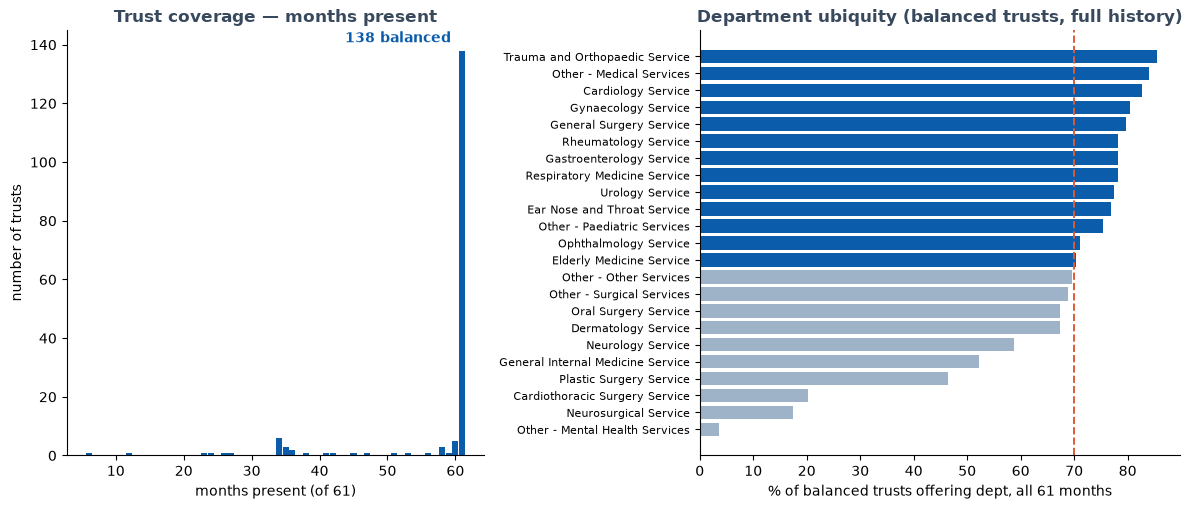

In [6]:
BLUE, CORAL, INK = '#0B5CAB', '#DC5B39', '#38495E'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})

vc = tc['months_present'].value_counts().sort_index()
ax1.bar(vc.index, vc.values, color=BLUE, width=0.9)
ax1.set_title('Trust coverage — months present', fontweight='bold', color=INK)
ax1.set_xlabel('months present (of 61)'); ax1.set_ylabel('number of trusts')
ax1.annotate(f'{int(vc.get(N, 0))} balanced', xy=(N, vc.get(N, 0)),
             xytext=(-8, 6), textcoords='offset points', ha='right', color=BLUE, fontweight='bold')

d = du.sort_values('pct_full')
colors = [BLUE if v >= 0.70 else '#9FB3C8' for v in d['pct_full']]
ax2.barh(d['dept_name'], d['pct_full'] * 100, color=colors)
ax2.axvline(70, color=CORAL, lw=1.4, ls='--')
ax2.set_title('Department ubiquity (balanced trusts, full history)', fontweight='bold', color=INK)
ax2.set_xlabel('% of balanced trusts offering dept, all 61 months')
ax2.tick_params(axis='y', labelsize=8)

for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / '03_missing_coverage.png', dpi=140, bbox_inches='tight')
print('saved', FIGS / '03_missing_coverage.png')
plt.show()

## Cell 7 — save outputs for Step 4

Three small CSVs (committed as reference): the balanced-panel trust list, the full series-coverage
table, and the department-ubiquity ranking.

In [7]:
tc.loc[tc['balanced']].sort_values('branch').to_csv(RESULTS / 'balanced_panel_trusts.csv', index=False)
s.to_csv(RESULTS / 'series_coverage.csv', index=False)
du.to_csv(RESULTS / 'dept_ubiquity.csv', index=False)
print('wrote:')
for f in ['balanced_panel_trusts.csv', 'series_coverage.csv', 'dept_ubiquity.csv']:
    print(' ', RESULTS / f)

wrote:
  /Users/nileshsarkar/Documents/FedOPD/notebooks/eda/results/balanced_panel_trusts.csv
  /Users/nileshsarkar/Documents/FedOPD/notebooks/eda/results/series_coverage.csv
  /Users/nileshsarkar/Documents/FedOPD/notebooks/eda/results/dept_ubiquity.csv


## Findings & decisions

- **Balanced panel = 138 of 172 trusts** present in all 61 months. The other 34 (mostly 56–60
  months) are partial-history — held out of the day-1 client pool, revisited only if a region is short.
- **Series:** 2,056 full · 416 true-gap (internal holes, ~4.3k missing months to fill/flag in Step 5)
  · 267 short-history (late-start service lines).
- **Structural zeros = 24% of balanced trust×dept cells** — legitimately absent (trust doesn't offer
  the specialty). Not imputed; handled by selecting a **shared** department set in Step 4.
- **Department ubiquity:** ~12 departments are offered with full history by ≥70% of balanced trusts
  (T&O, Cardiology, Gynaecology, General Surgery, Gastro, Respiratory, Urology, ENT, Ophthalmology…);
  Neurosurgery, Cardiothoracic and Mental Health are rare → natural to drop. **Selecting 10 is feasible.**

→ **Next (Step 4):** attach `trust → region`, count trusts per region, then apply
ubiquity + volume + regional-variation to lock the 7×10×10 panel.